In [99]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
sns.set_theme(style="whitegrid")

from qss.solver_options import brent_defaults
from qss.nkd import n_kd
from qss.chemical_potential import chemical_potential
from qss.distributions import DistType, prepare_2D_lattice_data
import tools.scientific_plot_v2 as sp
plotter = sp.ScientificPlotter()

In [100]:
MU_B  = 1# eV/T
N = 100
t = -1
# t_prim = 0.25
t_prim = 0

kx = np.linspace(-np.pi, np.pi, N, endpoint=False)
ky = np.linspace(-np.pi, np.pi, N, endpoint=False)
e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

In [101]:
# Band filling values
n_min = 0.8
n_max = 0.9
n_count = 2

# Magnetic field values
Ha_min = -3
Ha_max = 1
Ha_count = 20

# kBT values
kBT_min = -2
kBT_max = 2
kBT_count = 10

# U = 10
U = 1
# U = 0


distros = [DistType.SSL, DistType.FD, DistType.HUBBARD]#DistType.FD, DistType.FLB, DistType.NFL, DistType.NFLB, DistType.SSL]  # ND
# n  = np.array([ 0.8, 0.9], dtype=np.float64)  # NN
n  = np.linspace(n_min, n_max, n_count, dtype=np.float64)  # NN
# kBT = np.array([0.1, 1.0], dtype=np.float64)  # NB
kBT = np.logspace(kBT_min, kBT_max, kBT_count, dtype=np.float64)  # NB
# H_a = np.array([0.1, 0.5, 1.0], dtype=np.float64) # NH
H_a = np.logspace(Ha_min, Ha_max, Ha_count, dtype=np.float64) # NH
# H_a = np.concat([np.array([0.8]), H_a])

In [102]:
py_opts = brent_defaults(
    abs_tol=1e-9, 
    rel_tol=1e-6, 
    expand_factor=2.0,
    initial_step=1.0,  
    max_expands=164,
    max_iters=5000      
)
native_opts= py_opts.to_qss()

In [103]:
mu = Path("chemical_potential_nkd00.csv")
if  mu.exists():
    mu_df = pd.read_csv(mu)
    n = np.unique(mu_df["n"])
    distro = np.unique(mu_df["distro"])
    k_BT = np.unique(mu_df["k_BT"])
    kBT = k_BT
    H_a = np.unique(mu_df["H_a"])
    mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])

else:
    mu_df = chemical_potential(
        distros=distros,
        n_vals=n,
        kBT_vals=kBT,
        H_a_vals=H_a,
        N=N,
        E=e_k,
        U=U,
        solver_opts=native_opts,
        x0=-1.0,
        a0=-5.0,
        b0=5.0,
    )
    mu_df.to_csv("chemical_potential_nkd.csv")
mu_df

mu  iterations  converged      residual
distro  n   k_BT   H_a                                                      
SSL     0.8 0.01   0.001000    1.856695          23       True  7.419032e-09
        0.9 0.01   0.001000    2.830291          21       True  6.867770e-08
        0.8 0.01   0.001624    1.856613          23       True  7.706816e-08
        0.9 0.01   0.001624    2.830209          21       True  5.164696e-08
        0.8 0.01   0.002637    1.856401          23       True  2.483236e-08
...                                 ...         ...        ...           ...
HUBBARD 0.9 100.00 3.792690  -19.851303          22       True  9.075689e-09
        0.8 100.00 6.158482  -40.388586          23       True  1.771212e-08
        0.9 100.00 6.158482  -19.863110          22       True  8.040640e-09
        0.8 100.00 10.000000 -40.450842          23       True  6.513638e-08
        0.9 100.00 10.000000 -19.894257          22       True  3.277290e-08

[1200 rows x 4 columns]

In [104]:
mu = Path("chemical_potential_nkd.csv")
if  mu.exists():
    mu_df = pd.read_csv(mu)
    n = np.unique(mu_df["n"])
    distro = np.unique(mu_df["distro"])
    k_BT = np.unique(mu_df["k_BT"])
    kBT = k_BT
    H_a = np.unique(mu_df["H_a"])

    if "entropy" in mu_df.columns:
        entropy_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
    else:
        mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
        nkd_df = n_kd(mu_df, e_k)
        nkd_df.to_csv("chemical_potential_results.csv")

else:
    raise("Lack of the calculated chemical potential! Please run notebook number 2")
nkd_df

mu  iterations  converged      residual  \
distro  n   k_BT   H_a                                                         
SSL     0.8 0.01   0.001000    1.856695          23       True  7.419032e-09   
        0.9 0.01   0.001000    2.830291          21       True  6.867770e-08   
        0.8 0.01   0.001624    1.856613          23       True  7.706816e-08   
        0.9 0.01   0.001624    2.830209          21       True  5.164696e-08   
        0.8 0.01   0.002637    1.856401          23       True  2.483236e-08   
...                                 ...         ...        ...           ...   
HUBBARD 0.9 100.00 3.792690  -19.851303          22       True  9.075689e-09   
        0.8 100.00 6.158482  -40.388586          23       True  1.771212e-08   
        0.9 100.00 6.158482  -19.863110          22       True  8.040640e-09   
        0.8 100.00 10.000000 -40.450842          23       True  6.513638e-08   
        0.9 100.00 10.000000 -19.894257          22       True  3.277290e-08   

                                   nkd  
distro  n   k_BT   H_a                  
SSL     0.8 0.01   0.001000   0.197685  
        0.9 0.01   0.001000   0.222491  
        0.8 0.01   0.001624   0.194495  
        0.9 0.01   0.001624   0.218901  
        0.8 0.01   0.002637   0.186406  
...                                ...  
HUBBARD 0.9 100.00 3.792690   0.202938  
        0.8 100.00 6.158482   0.160188  
        0.9 100.00 6.158482   0.202793  
        0.8 100.00 10.000000  0.159830  
        0.9 100.00 10.000000  0.202413  

[1200 rows x 5 columns]

In [105]:
# # Select a magnetic field to plot
# H_a_plot = H_a[-1]
# kBT_plot = kBT

# # Plot
# plotter.plot_scalar_result(
#     results=nkd_df,
#     x_param="n",
#     y_col="nkd",
#     y_label=r"$n_{k_d}$",
#     fixed_params={"H_a": H_a_plot},
#     distros=[d.name for d in distros],
#     subplots_param="kBT",
#     subplots_vals=kBT_plot,
#     cols=1,
#     U=U,
#     figsize=(16, 8)
# )
# plt.show()

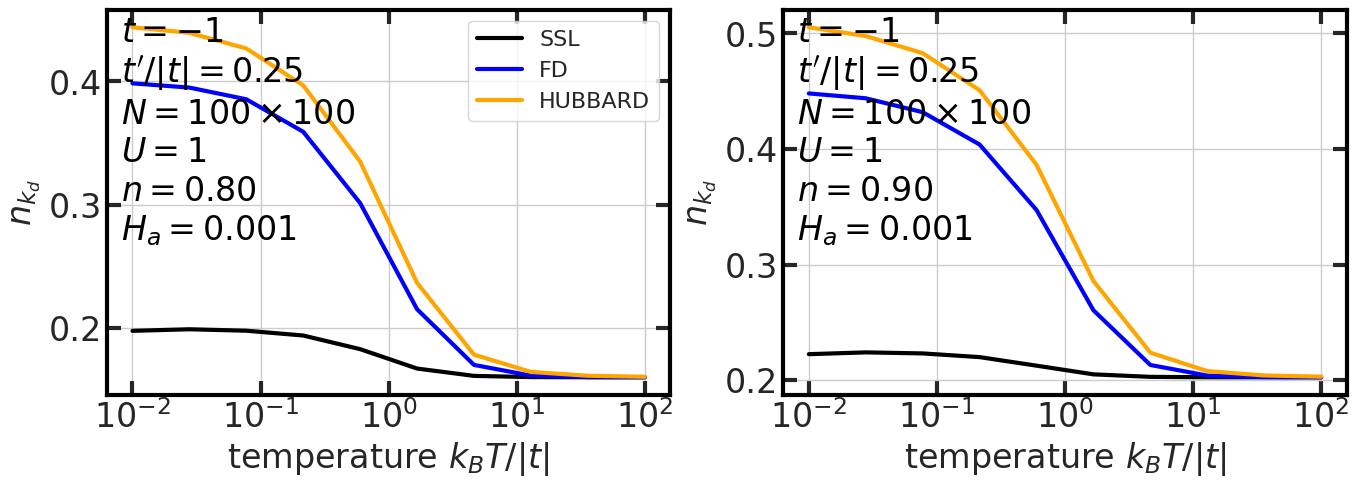

In [106]:
n_plot = n[-5:]
H_a_plot = H_a[0]

# Plot
plotter.plot_scalar_result(
    results=nkd_df,
    x_param="k_BT",
    y_col="nkd",
    y_label=r"$n_{k_d}$",
    fixed_params={"H_a": H_a_plot},
    distros=[d.name for d in distros],
    subplots_param="n",
    subplots_vals=n_plot,
    cols=2,
    U=U,
    figsize=(8, 5),
    xscale="log"
)
plt.show()

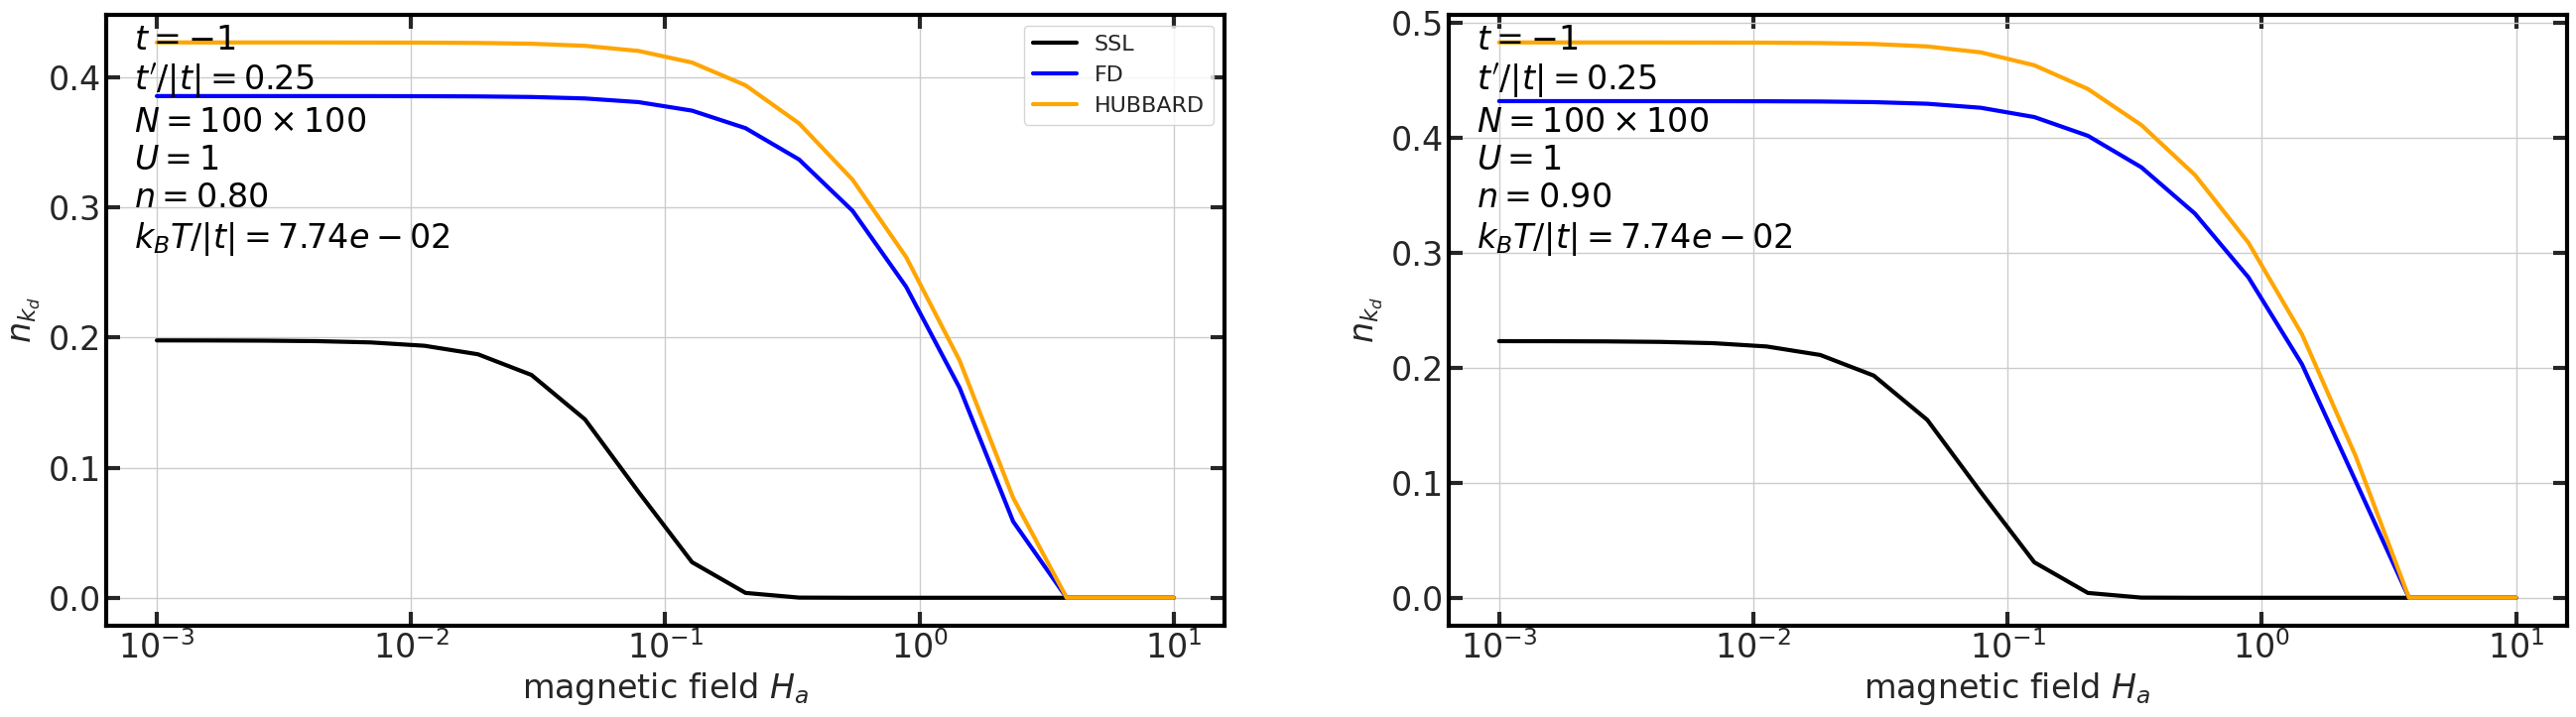

In [107]:
n_plot = n[-2:]
kBT_plot = kBT[2]
plotter.plot_scalar_result(
    results=nkd_df,
    x_param="H_a",
    y_col="nkd",
    y_label=r"$n_{k_d}$",
    fixed_params={"kBT": kBT_plot},
    distros=[d.name for d in distros],
    subplots_param="n",
    subplots_vals=n_plot,
    cols=2,
    U=U,
    figsize=(16,8),
    xscale="log"
)
plt.show()

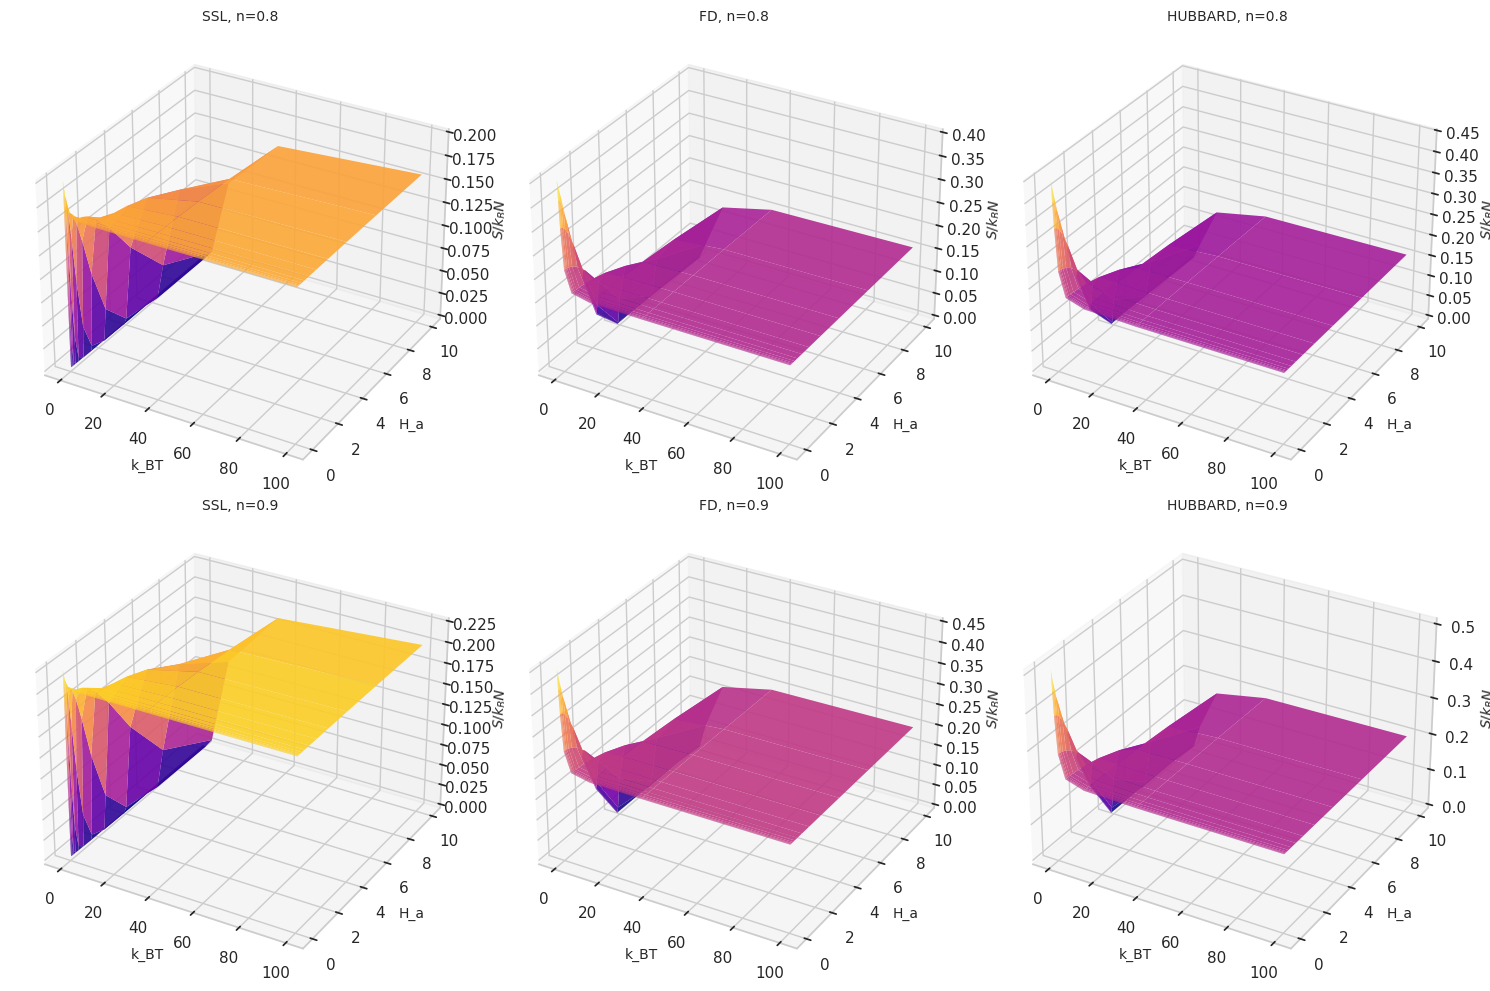

In [108]:
# Example: Plot Entropy vs Temperature (k_BT) and Magnetic Field (H_a)
# for different band fillings (n)

# Select a few n values for the rows
n_rows = [n[0], n[len(n)//2]] 
plotter.plot_3d_results(
    results=nkd_df,
    row_param="n",       # Vary n across rows
    row_vals=n,     # Specific n values
    x_param="k_BT",      # X axis
    y_param="H_a",       # Y axis
    z_label=r"$S / k_B N$",
    z_col="nkd",          # or "entropy" if you have calculated it
    distros=[d.name for d in distros],
    # figsize=(15, 10)
)
plt.show()